# Problema 5: Agrupamento com k-Means (Clientes Atacadistas)

Segmentação de clientes com base no gasto anual em 6 categorias de produtos (em unidades monetárias m.u.):
- `Fresh`: Gastos anuais com produtos frescos / hortifrúti
- `Milk`: Gastos anuais com produtos lácteos
- `Grocery`: Gastos anuais com mercearia / secos e molhados
- `Frozen`: Gastos anuais com congelados
- `Detergents_Paper`: Gastos anuais com higiene, detergentes e papel
- `Delicassen`: Gastos anuais com frios e delicatéssen
- Variáveis de validação externa:
  - `Channel`: Canal de compra (1 = Horeca [Hotéis/Restaurantes/Cafés], 2 = Varejo)
  - `Region`: Região (1 = Lisboa, 2 = Porto, 3 = Outras)


### 1. Importação das Bibliotecas

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA

os.makedirs('graficos', exist_ok=True)


### 2. Tarefa 1: Preparação dos Dados e Separação de Variáveis
Separamos `Channel` e `Region` (reservados exclusivamente para validação externa) e inspecionamos os 6 gastos anuais.


In [2]:
dados = pd.read_csv('dataset/Wholesale_customers_data.csv')
categorias_gasto = ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']

canais = dados['Channel']   # 1 = Horeca, 2 = Retail
regioes = dados['Region']   # 1 = Lisboa, 2 = Porto, 3 = Outras
X_gastos = dados[categorias_gasto]

X_gastos.describe().round(1)


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.0,440.0,440.0,440.0,440.0,440.0
mean,12000.3,5796.3,7951.3,3071.9,2881.5,1524.9
std,12647.3,7380.4,9503.2,4854.7,4767.9,2820.1
min,3.0,55.0,3.0,25.0,3.0,3.0
25%,3127.8,1533.0,2153.0,742.2,256.8,408.2
50%,8504.0,3627.0,4755.5,1526.0,816.5,965.5
75%,16933.8,7190.2,10655.8,3554.2,3922.0,1820.2
max,112151.0,73498.0,92780.0,60869.0,40827.0,47943.0


#### Gráfico: Distribuição dos Gastos Originais (Forte Assimetria à Direita)
Plotamos individualmente os dados brutos para evidenciar a cauda longa e os grandes compradores.


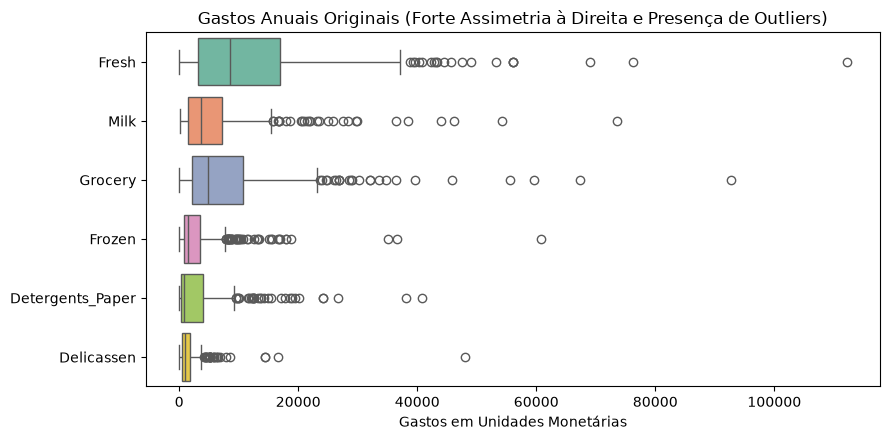

In [3]:
plt.figure(figsize=(9, 4.5))
sns.boxplot(data=X_gastos, orient='h', palette='Set2')
plt.title('Gastos Anuais Originais (Forte Assimetria à Direita e Presença de Outliers)')
plt.xlabel('Gastos em Unidades Monetárias')
plt.tight_layout()
plt.savefig('graficos/distribuicao_gastos_original.png', dpi=300)
plt.show()


#### Transformação Logarítmica e Padronização Z-score
- **Por que $\log(1+x)$?** Encolhe a cauda longa à direita, tornando as distribuições aproximadamente normais e reduzindo o impacto de outliers gigantescos.
- **Por que padronização Z-score?** O $k$-Means calcula a distância Euclidiana aos centroides. Sem padronização, a categoria `Fresh` (média 12.000) dominaria completamente os grupos em detrimento de `Delicassen` (média 1.500).


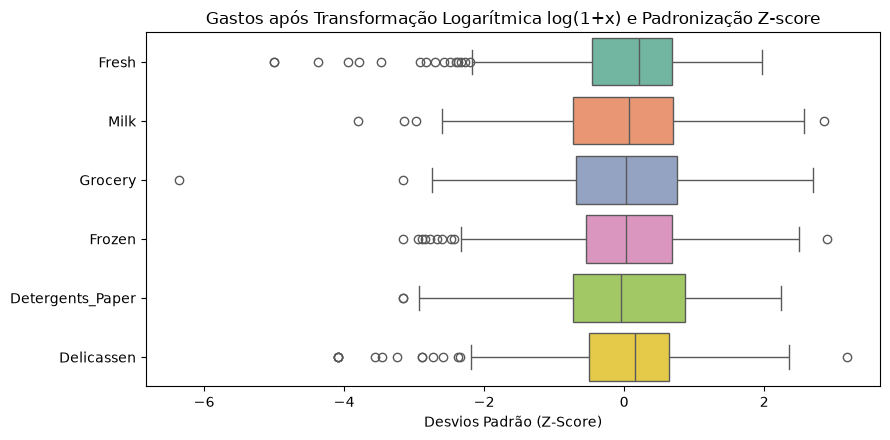

In [4]:
X_log = np.log1p(X_gastos)
escalonador = StandardScaler()
X_pad = escalonador.fit_transform(X_log)

plt.figure(figsize=(9, 4.5))
sns.boxplot(data=pd.DataFrame(X_pad, columns=categorias_gasto), orient='h', palette='Set2')
plt.title('Gastos após Transformação Logarítmica log(1+x) e Padronização Z-score')
plt.xlabel('Desvios Padrão (Z-Score)')
plt.tight_layout()
plt.savefig('graficos/distribuicao_gastos_transformados.png', dpi=300)
plt.show()


#### Gráfico: Matriz de Correlação e o Par `Grocery` – `Detergents_Paper`
Inspecionamos o alinhamento das compras no atacado.


Correlação entre Grocery e Detergents_Paper: 0.9246


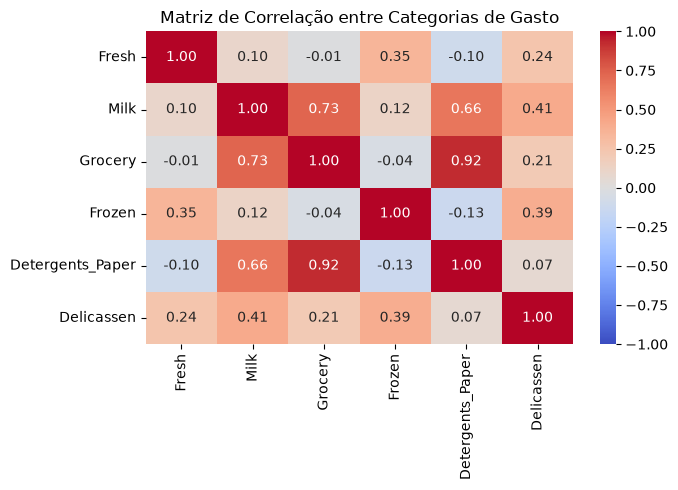

In [5]:
matriz_corr = X_gastos.corr()
print(f"Correlação entre Grocery e Detergents_Paper: {matriz_corr.loc['Grocery', 'Detergents_Paper']:.4f}")

plt.figure(figsize=(7, 5))
sns.heatmap(matriz_corr, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Matriz de Correlação entre Categorias de Gasto')
plt.tight_layout()
plt.savefig('graficos/matriz_correlacao_gastos.png', dpi=300)
plt.show()


**Comentário Comercial:**  
A correlação entre `Grocery` e `Detergents_Paper` é de **+0.9246**. Clientes que compram mercadorias alimentícias não perecíveis quase invariavelmente abastecem suas prateleiras com produtos de limpeza doméstica e papel. Trata-se do padrão típico de **supermercados e mercearias**.


### 3. Tarefa 2: Ausência de Divisão Treino/Teste e Validação em Agrupamento
No aprendizado supervisionado, o objetivo é avaliar a generalização sobre rótulos verdadeiros $y$. No aprendizado não supervisionado, não existe rótulo verdadeiro nem gabarito. Separar teste é inadequado, pois o objetivo é a análise exploratória da carteira completa. A validação depende da qualidade geométrica interna (silhueta) e da utilidade comercial prática.


### 4. Tarefa 3: Escolha do Número de Grupos ($k = 2$ a $10$)
Calculamos a inércia e o coeficiente de silhueta para cada valor de $k$.


In [6]:
valores_k = list(range(2, 11))
inercias = []
silhuetas = []

for k in valores_k:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_pad)
    inercias.append(km.inertia_)
    sil = silhouette_score(X_pad, km.labels_)
    silhuetas.append(sil)
    print(f"k = {k:2d} | Inércia = {km.inertia_:.2f} | Silhueta Média = {sil:.4f}")


k =  2 | Inércia = 1844.06 | Silhueta Média = 0.2903
k =  3 | Inércia = 1553.42 | Silhueta Média = 0.2594
k =  4 | Inércia = 1386.86 | Silhueta Média = 0.1885
k =  5 | Inércia = 1266.15 | Silhueta Média = 0.1916
k =  6 | Inércia = 1174.76 | Silhueta Média = 0.2009


k =  7 | Inércia = 1086.36 | Silhueta Média = 0.1958
k =  8 | Inércia = 1028.49 | Silhueta Média = 0.1852
k =  9 | Inércia = 973.14 | Silhueta Média = 0.1965
k = 10 | Inércia = 932.00 | Silhueta Média = 0.1905


#### Gráfico: Método do Cotovelo (Inércia vs. $k$)
Analisamos a redução marginal da inércia (soma dos quadrados intra-cluster).


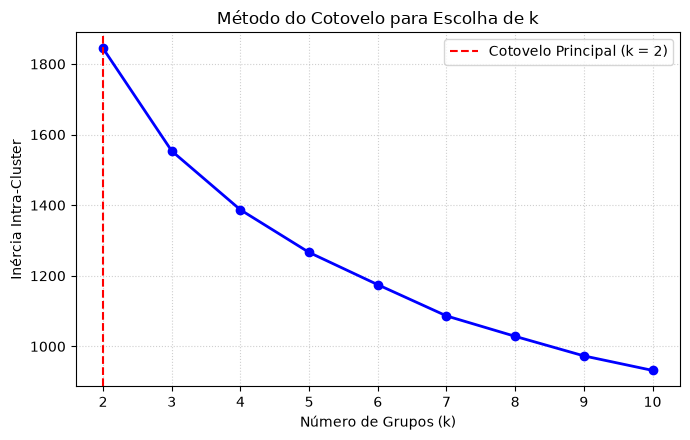

In [7]:
plt.figure(figsize=(7, 4.5))
plt.plot(valores_k, inercias, 'bo-', lw=2)
plt.axvline(2, color='red', linestyle='--', label='Cotovelo Principal (k = 2)')
plt.xlabel('Número de Grupos (k)')
plt.ylabel('Inércia Intra-Cluster')
plt.title('Método do Cotovelo para Escolha de k')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.savefig('graficos/metodo_cotovelo.png', dpi=300)
plt.show()


**Por que a inércia decresce monotonicamente com $k$?**  
Ao aumentar $k$, cada ponto só pode ficar mais próximo ou à mesma distância de algum centroide. No caso limite $k = N$ (um centroide por cliente), a inércia é exatamente **zero**, mas o agrupamento não gera nenhuma simplificação da realidade.


#### Gráfico: Coeficiente de Silhueta Médio vs. $k$
Avaliamos a qualidade geométrica de separação e coesão dos grupos.


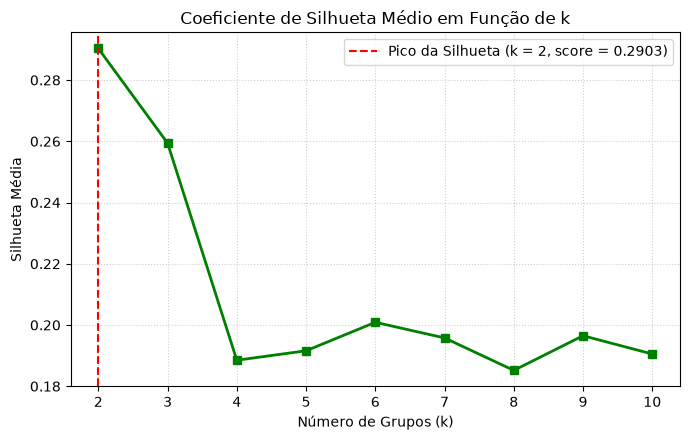

In [8]:
plt.figure(figsize=(7, 4.5))
plt.plot(valores_k, silhuetas, 'gs-', lw=2)
plt.axvline(2, color='red', linestyle='--', label='Pico da Silhueta (k = 2, score = 0.2903)')
plt.xlabel('Número de Grupos (k)')
plt.ylabel('Silhueta Média')
plt.title('Coeficiente de Silhueta Médio em Função de k')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.savefig('graficos/coeficiente_silhueta.png', dpi=300)
plt.show()


### 5. Tarefa 4: Inicialização e Convergência (`random` vs `k-means++`)
Executamos 10 repetições com sementes diferentes para cada inicializador.


In [9]:
inercia_rnd = []
inercia_pp = []

for s in range(10):
    km_r = KMeans(n_clusters=2, init='random', n_init=1, random_state=s).fit(X_pad)
    inercia_rnd.append(km_r.inertia_)
    km_p = KMeans(n_clusters=2, init='k-means++', n_init=1, random_state=s).fit(X_pad)
    inercia_pp.append(km_p.inertia_)

print(f"init='random'   : Média = {np.mean(inercia_rnd):.2f} | Desvio Padrão = {np.std(inercia_rnd):.4f}")
print(f"init='k-means++': Média = {np.mean(inercia_pp):.2f} | Desvio Padrão = {np.std(inercia_pp):.4f}")


init='random'   : Média = 1844.08 | Desvio Padrão = 0.0289
init='k-means++': Média = 1844.09 | Desvio Padrão = 0.0308


**Como o `k-means++` mitiga o problema de mínimos locais?**  
O algoritmo escolhe o primeiro centroide aleatoriamente e cada centroide subsequente com probabilidade proporcional ao quadrado da distância ao centroide mais próximo já alocado ($P(x) \propto D(x)^2$). Isso garante que os centros iniciais comecem bem afastados, acelerando a convergência.


### 6. Tarefa 5: Interpretação Comercial e Validação Externa
Revertemos os centroides para unidades monetárias originais e nomeamos os perfis.


In [10]:
modelo_k2 = KMeans(n_clusters=2, init='k-means++', n_init=10, random_state=42)
grupos = modelo_k2.fit_predict(X_pad)

# Reversão: desfazendo padronização e expm1
centroides_log = escalonador.inverse_transform(modelo_k2.cluster_centers_)
centroides_orig = np.expm1(centroides_log)

df_cent = pd.DataFrame(centroides_orig, columns=categorias_gasto,
                       index=['Perfil 0 (Horeca / Alimentação Fora)', 'Perfil 1 (Varejo / Supermercados)'])
df_cent.round(1)


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Perfil 0 (Horeca / Alimentação Fora),8580.6,1753.7,2274.4,2063.8,287.4,649.4
Perfil 1 (Varejo / Supermercados),4013.9,8061.6,12051.1,953.5,4035.6,1022.1


#### Gráfico: Perfil de Consumo dos Agrupamentos
Comparamos os gastos médios anuais em cada categoria.


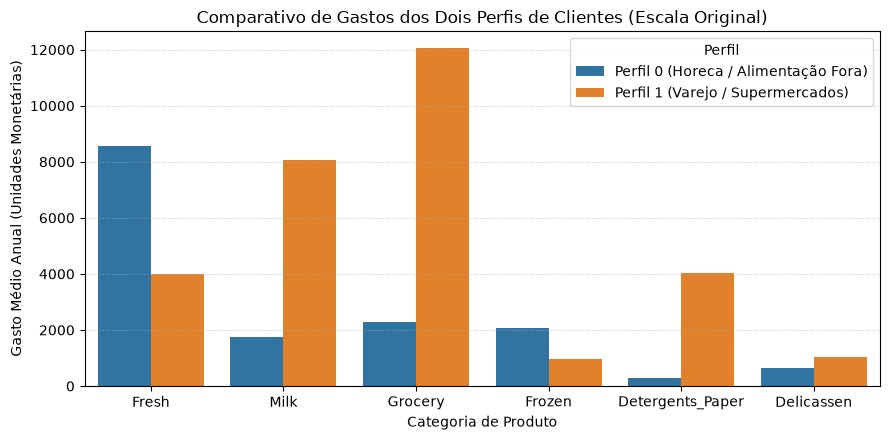

In [11]:
df_plot = df_cent.T.reset_index().melt(id_vars='index', var_name='Perfil', value_name='Gasto Médio Anual')

plt.figure(figsize=(9, 4.5))
sns.barplot(data=df_plot, x='index', y='Gasto Médio Anual', hue='Perfil', palette=['#1f77b4', '#ff7f0e'])
plt.title('Comparativo de Gastos dos Dois Perfis de Clientes (Escala Original)')
plt.xlabel('Categoria de Produto')
plt.ylabel('Gasto Médio Anual (Unidades Monetárias)')
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.savefig('graficos/perfil_centroides.png', dpi=300)
plt.show()


#### Validação Externa com `Channel` e `Region`
Verificamos a concordância dos grupos com o canal de venda real e a região geográfica.


In [12]:
tab_canal = pd.crosstab(grupos, canais.map({1: 'Horeca (1)', 2: 'Retail (2)'}), rownames=['Cluster'])
print("Tabela de Contingência com Channel:")
print(tab_canal)

ari = adjusted_rand_score(canais, grupos)
print(f"\nÍndice Rand Ajustado (ARI) com Channel: {ari:.4f}")

tab_regiao = pd.crosstab(grupos, regioes.map({1: 'Lisboa', 2: 'Porto', 3: 'Outras'}), rownames=['Cluster'])
print("\nTabela de Contingência com Region:")
print(tab_regiao)


Tabela de Contingência com Channel:
Channel  Horeca (1)  Retail (2)
Cluster                        
0               244           8
1                54         134

Índice Rand Ajustado (ARI) com Channel: 0.5135

Tabela de Contingência com Region:
Region   Lisboa  Outras  Porto
Cluster                       
0            48     176     28
1            29     140     19


#### Gráfico: Projeção dos Grupos em 2D por PCA e Limitações do k-Means
Avaliamos a distribuição dos grupos e os centroides no plano de maior variância.


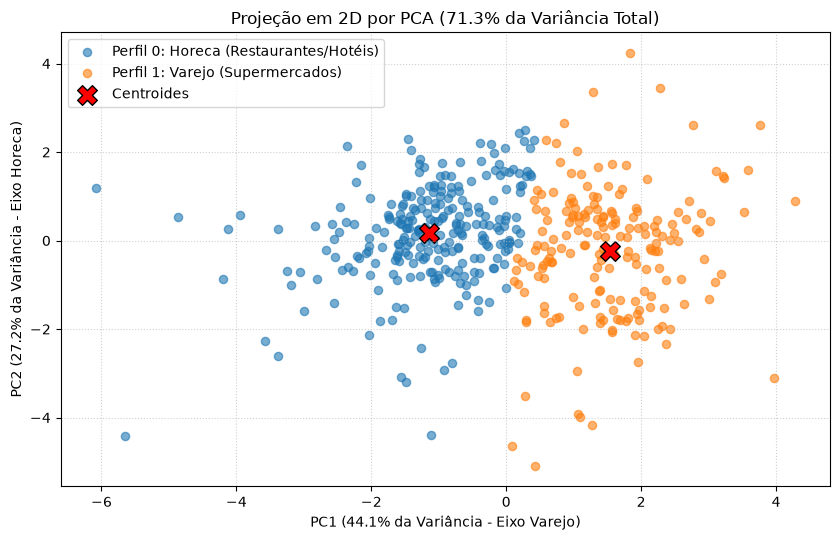

In [13]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_pad)
cent_pca = pca.transform(modelo_k2.cluster_centers_)

plt.figure(figsize=(8.5, 5.5))
cores = ['#1f77b4', '#ff7f0e']
labels = ['Perfil 0: Horeca (Restaurantes/Hotéis)', 'Perfil 1: Varejo (Supermercados)']

for c in range(2):
    plt.scatter(X_pca[grupos == c, 0], X_pca[grupos == c, 1],
                color=cores[c], label=labels[c], alpha=0.6, s=35)

plt.scatter(cent_pca[:, 0], cent_pca[:, 1], c='red', marker='X', s=200, edgecolors='black', label='Centroides')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% da Variância - Eixo Varejo)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% da Variância - Eixo Horeca)')
plt.title('Projeção em 2D por PCA (71.3% da Variância Total)')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.savefig('graficos/projecao_pca.png', dpi=300)
plt.show()


### Discussão Final e Limitações do $k$-Means
1. **Reconstrução do Canal:** O algoritmo, sem ter visto o canal de venda, separou Horeca de Retail com concordância de $85.9\%$ e $\text{ARI} = 0.5135$. O canal Horeca compra muito mais `Fresh` e `Frozen`, enquanto o Varejo compra até 14 vezes mais `Grocery` e `Detergents_Paper`.
2. **Independência Geográfica:** A proporção geográfica (Lisboa, Porto, Interior) é idêntica nos dois grupos, confirmando que a região não dita o perfil de consumo.
3. **Limitações do $k$-Means:**
   - **Forma esférica:** O algoritmo assume agrupamentos esféricos de variância similar, tendo dificuldade com feixes elípticos alongados como o par `Grocery`–`Detergents_Paper`.
   - **Sensibilidade a Outliers:** Clientes com consumo monumental puxam os centroides na sua direção, alterando o centro de gravidade da massa de clientes comuns.
